In [2]:
import numpy as np
import time
import sklearn.datasets as datasets
from sklearn.model_selection import train_test_split as split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

np.random.seed(0)

In [3]:
# Helper functions from the bandits TP
def cumul_regret(regrets: list[float]):
    return np.cumsum(regrets)

def plot_mean_std_cumul_regret(regret_matrix: list[list[float]], algo_name: str):
    means = regret_matrix.mean(axis=0)
    stds = regret_matrix.std(axis=0)
    plt.plot(means, label=algo_name)
    plt.fill_between(np.arange(len(means)), means - stds, means + stds, alpha=0.1)

## 1. Learning a classifier with contextual bandits
A supervised classification problem $(X,y)$ with $X$ the dataset features in $\mathbb{R}^{N \times d}$ and $y$ the classes vector in $\{0,...,K-1\}^N$ can be formulated as a [contextual bandits problem](https://tor-lattimore.com/downloads/book/book.pdf) as follows. At time $t$, a learner observes a context vector $x_n$ drawn at random from $X$. The learner then pulls an arm $a \in A = \{0, ..., K-1\}$ based on $x_n$ and receives a binary reward $\mathbb{1}_{\{a=y_n\}}$. Learning a function $f:X\rightarrow A$ that maximizes the expected cumulative reward $\mathbb{E}_{x_n \sim X}[\sum_{t=0}^T \mathbb{1}_{\{f(x_n)=y_n\}}]$ is learning a classifier that minimizes the misclassification rate.

For reference, see section 5.1 of Dudík, Langford and Li, [Doubly Robust Policy Evaluation and Learning](https://arxiv.org/abs/1103.4601), ICML 2011.

In [4]:
class ClassLabelArm:
    def __init__(self, label:int):
        self.label = label

    def sample_reward(self, predicted_label:int):
        return self.label == predicted_label

In [5]:
## Definition of the problem

class SupervisedLearningAsBandits:
    def __init__(self, X:list[list[float]], y:list[int]):
        self.X = X
        self.y = y
        self.arms = [ClassLabelArm(k) for k in sorted(set(y))]
        self.current_context = None
        self._current_true_label = None

    def get_context(self):
        rdm_context_idx = np.random.randint(len(self.X))
        self.current_context = self.X[rdm_context_idx]
        self._current_true_label = self.y[rdm_context_idx]
        return self.current_context

    def sample(self, arm_number:int):
        reward = self.arms[arm_number].sample_reward(self._current_true_label)
        regret = 1 - reward
        return reward, regret

## 2. Contextual bandits algorithms
We now provide a base class for learning algorithms that pull an arm depending on the observed context. As for classical multi-armed bandits, one can define a Uniform Sampler that pulls arms independently of the context. The counterpart of this random algorithm is a learner (that is not one) that stores in memory all the observed contexts and the associated true class labels. Note that the latter algorithm is memory inefficient and cannot generalize to unseen data. Furthermore, a learner must not observe the true class label when an arm is pulled, but only the 0-1 reward. The memory-based bandits algorithm is provided as an unrealistic baseline.

The method `predict` returns the class predicted for a context after learning, and is used to compute misclassification rates. By default it is `arm_to_pull`. An algorithm that explores can override it to return its best guess without exploration.

In [6]:
class ContextualBanditsAlgo:
    def __init__(self, contextual_bandits:SupervisedLearningAsBandits):
        self.mab = contextual_bandits
        self.rewards = []
        self.regrets = []
        self.arms_drawn = []

    def arm_to_pull(self, context:list[float]):
        raise NotImplementedError

    def predict(self, context:list[float]):
        return self.arm_to_pull(context)

    def sampling(self, timesteps_T:int):
        raise NotImplementedError

class UniformSamplingForCB(ContextualBanditsAlgo):
    def __init__(self, contextual_bandits:SupervisedLearningAsBandits):
        super().__init__(contextual_bandits)

    def arm_to_pull(self, context:list[float]):
        return np.random.randint(len(self.mab.arms))

    def sampling(self, timesteps_T:int):
        for t in range(timesteps_T):
            ctxt = self.mab.get_context()
            arm_to_pull = self.arm_to_pull(ctxt)
            reward, regret = self.mab.sample(arm_to_pull)
            self.rewards.append(reward)
            self.regrets.append(regret)
            self.arms_drawn.append(arm_to_pull)

class ContextMemory(ContextualBanditsAlgo):
    def __init__(self, contextual_bandits:SupervisedLearningAsBandits):
        super().__init__(contextual_bandits)
        self.memory = dict()

    def arm_to_pull(self, context:list[float]):
        if tuple(context) not in self.memory.keys():
            return np.random.randint(len(self.mab.arms))
        else:
            return self.memory[tuple(context)]

    def sampling(self, timesteps_T:int):
        for t in range(timesteps_T):
            ctxt = self.mab.get_context()
            arm_to_pull = self.arm_to_pull(ctxt)
            reward, regret = self.mab.sample(arm_to_pull)
            ##### YOU SHOULD NOT ACCESS THE TRUE LABEL ######
            self.memory[tuple(ctxt)] = self.mab._current_true_label
            #################################################
            self.rewards.append(reward)
            self.regrets.append(regret)
            self.arms_drawn.append(arm_to_pull)

## Design Choices 

#### LinUCB

In [7]:
class LinUCB(ContextualBanditsAlgo):
    def __init__(self, contextual_bandits:SupervisedLearningAsBandits, alpha: float = 1.0, lambda_reg: float = 1.0):
        super().__init__(contextual_bandits)
        self.alpha = alpha
        self.lambda_reg = lambda_reg
        
        # Initialize A_a and b_a for each arm
        self.A = [lambda_reg * np.eye(self.mab.X.shape[1]) for _ in range(len(self.mab.arms))]
        self.b = [np.zeros(self.mab.X.shape[1]) for _ in range(len(self.mab.arms))]
    
    def compute_ucb_index(self, arm: int, context: np.ndarray) -> float:
        A_inv = np.linalg.inv(self.A[arm])
        theta_hat = A_inv.dot(self.b[arm])
        ucb = theta_hat.dot(context) + self.alpha * np.sqrt(context.dot(A_inv).dot(context))
        return ucb

    def arm_to_pull(self, context:list[float]):
            ucb_indices = [self.compute_ucb_index(arm, context) for arm in range(len(self.mab.arms))]
            return np.argmax(ucb_indices)
    
    def sampling(self, timesteps_T: int):
        for t in range(timesteps_T):
            # Generate context
            context = self.mab.get_context()
            arm_to_pull = self.arm_to_pull(context)
            
            # Compute UCB index for all arms
            # Pull arm and observe reward
            reward, regret = self.mab.sample(arm_to_pull)
            self.rewards.append(reward)
            self.regrets.append(regret)
            self.arms_drawn.append(arm_to_pull)
            
            # Update statistics
            self.A[arm_to_pull] += np.outer(context, context)
            self.b[arm_to_pull] += reward * context

### Thompson Sampling for Contextual Bandits

[https://proceedings.mlr.press/v28/agrawal13.pdf]  
(Shipra Agrawal, Navin Goyal)

In [8]:
class ThompsonSampling(ContextualBanditsAlgo):
    def __init__(self, contextual_bandits:SupervisedLearningAsBandits, seed: int = 0, v: float = 1.0):
        super().__init__(contextual_bandits)
        self.v = v ## Act as our exploration parameter (related to the variance)
        self.num_arms = len(self.mab.arms)
        self.rng = np.random.default_rng(seed=seed)
        
        # Initialize B
        self.B = [np.eye(self.mab.X.shape[1]) for _ in range(self.num_arms)]
        self.mean = [np.zeros(self.mab.X.shape[1]) for _ in range(self.num_arms)]
        self.f = [np.zeros(self.mab.X.shape[1]) for _ in range(self.num_arms)]

    def arm_to_pull(self, context:list[float]):
        acting_prob = np.zeros(self.num_arms)
        for k in range(self.num_arms):
            covar = self.v**2 * np.linalg.inv(self.B[k])
            mu_hat = self.rng.multivariate_normal(self.mean[k], covar)
            acting_prob[k] = mu_hat @ context
        return np.argmax(acting_prob)
    
    def sampling(self, timesteps_T: int):
        for t in range(timesteps_T):
            # Generate context
            context = self.mab.get_context()
            arm_to_pull = self.arm_to_pull(context)
            
            # Compute UCB index for all arms
            # Pull arm and observe reward
            reward, regret = self.mab.sample(arm_to_pull)
            self.rewards.append(reward)
            self.regrets.append(regret)
            self.arms_drawn.append(arm_to_pull)
            
            # Update statistics
            self.B[arm_to_pull] += np.outer(context, context)
            self.f[arm_to_pull] += context * reward
            self.mean[arm_to_pull] = np.linalg.inv(self.B[arm_to_pull]) @ self.f[arm_to_pull]

#### Neural-UCB (Neural Contextual Bandits with UCB-based Exploration)
[https://arxiv.org/abs/1911.04462]  
(Dongruo Zhou, Lihong Li, Quanquan Gu)

In [9]:
import torch
import torch.nn as nn

class NeuralUCB(ContextualBanditsAlgo):
    def __init__(self, contextual_bandits:SupervisedLearningAsBandits, 
                 gamma: float = 1.0, 
                 lambda_reg: float = 1.0, 
                 L: int = 1, 
                 m: int = 10,
                 J: int = 100,
                 tau: float = 0.001,
                 gamma_decay: float = 0.99,
                 inverse_diag: bool = False,
                 update_freq: int = 100,
                 warmup: int = 100
                 ):
        super().__init__(contextual_bandits)
        self.lambda_reg = lambda_reg
        self.L = L
        self.m = m
        self.d = self.mab.X.shape[1]
        self.num_arms = len(self.mab.arms)
        self.theta = self.initTheta(input_dim=(self.d*self.num_arms*2), m=self.m, output_dim=1, depth=self.L) ## input dim adapted to the normalized and contextualised input vector
        self.theta_0 = [w.clone().detach() for w in self.theta]
        self.p = self.m + self.num_arms*self.d*2*self.m + self.m**2*(self.L-1)

        # inverse of Z
        self.inverse_diag = inverse_diag
        if self.inverse_diag:
            self.Z_diag = self.lambda_reg * torch.ones(self.p, dtype=torch.float32)
        else:
            self.Z = self.lambda_reg *torch.eye(self.p, dtype=torch.float32) 
            self.Z_inv = torch.linalg.inv(self.Z) 

        # Train parameters
        self.update_freq = update_freq
        self.warmup = warmup
        self.gxaflat = None
        self.gamma = gamma
        self.gamma_decay = gamma_decay
        self.J = J
        self.tau = tau

    def arm_to_pull(self, context:list[float]):
        nn_ucb_indices = [self.compute_nn_ucb_index(arm, context) for arm in range(self.num_arms)]
        indice_max = np.argmax([x[0] for x in nn_ucb_indices])
        self.gxaflat = nn_ucb_indices[indice_max][1]
        return indice_max, self.create_context_for_arm(torch.tensor(context, dtype=torch.float32), indice_max, self.num_arms)

    def compute_nn_ucb_index(self, arm: int, context: np.ndarray) -> float:
            context_red = self.create_context_for_arm(
                torch.tensor(context, dtype=torch.float32), 
                arm, 
                self.num_arms) ## Redimensionning the context with regard to the arms to be selected

            fx = self.h(context_red, self.theta) ## f(x; theta)
            ## g(x; theta) -> will be a list of matrix so we flatten it
            gxa = self.g(context_red, self.theta) 
            gxaflat = torch.cat([grad.flatten() for grad in gxa]).detach()
            if self.inverse_diag:
                ucb = fx + self.gamma * torch.sqrt( (gxaflat**2/self.Z_diag).sum()/self.m ) 
            else:
                ucb = fx + self.gamma * torch.sqrt( (gxaflat.T @ self.Z_inv @ gxaflat)/self.m )
            return ucb.item(), gxaflat
    
    def sampling(self, timesteps_T: int):
        replay_x = []
        replay_r = []
    
        for t in range(timesteps_T):
            if t % 100 == 0:
                self.gamma *= self.gamma_decay
                
            # Generate context
            context = self.mab.get_context()
            arm_to_pull, context_red = self.arm_to_pull(context)
            
            # Compute UCB index for all arms
            # Pull arm and observe reward
            reward, regret = self.mab.sample(arm_to_pull)
            self.rewards.append(reward)
            self.regrets.append(regret)
            self.arms_drawn.append(arm_to_pull)

            ## Adding the context and reward to the history for training
            replay_x.append(context_red)
            replay_r.append(reward)
            
            # Update statistics
            if self.inverse_diag:
                self.Z_diag += (self.gxaflat**2)/self.m
            else:
                # Takes a lot of time
                self.Z += torch.outer(self.gxaflat, self.gxaflat) / self.m 
                self.Z_inv = torch.linalg.inv(self.Z) 
            if ((t+1) % self.update_freq == 0 and (t+1) > self.warmup):
                self.trainNN(xt=torch.stack(replay_x), rt=torch.tensor(replay_r, dtype=torch.float32))

## ------------------------------------------------------------------ Neural Network part ------------------------------------------------------------------ ##
 
    def create_context_for_arm(self, x: torch.Tensor, arm: int, nb_arms: int):
        ''' 
        Create a context vector associated to each arm (1D)
        The vector will be of size (d*nb_arms) with x inserted in the position starting at k*d (with k the arm index)
        '''
        d = x.shape[0]
        ## Normalisation from the section 4.2
        x = x / (torch.norm(x) + 1e-8)
        v = torch.zeros(d * nb_arms)
        v[arm*d:(arm+1)*d] = x
        return torch.cat((v, v), dim=0) / np.sqrt(2)

    def initTheta(self, input_dim, m, output_dim, depth=1):
        '''  
        - input_dim: dimension of the features ('d' in the article)
        - m: dimension of the hidden layer ('m' in the article)
        - depth: number of hidden layers ('(L-1)' in the article)
        - output_dim : dimension of the output ('1' in the article)
        Asumption : m and input_dim are even
        '''
        d = input_dim
        weights = []
        w_1 = np.random.normal(0, (np.sqrt(4 / m)), (m //2, d//2))
        W_1 = np.block([
            [w_1, np.zeros((m//2, d//2))],
            [np.zeros((m//2, d//2)), w_1]
        ])
        weights.append(W_1)
        for i in range(depth-1):
            w_i = np.random.normal(0, (np.sqrt(4 / m)), (m//2, m//2))
            W_i = np.block([
                [w_i, np.zeros((m//2, m//2))],
                [np.zeros((m//2, m//2)), w_i]
            ])
            weights.append(W_i)
        w_l = np.random.normal(0, (np.sqrt(2 / m)), (output_dim, m//2))
        W_L = np.concatenate([w_l, -w_l], axis=1)
        weights.append(W_L)
        return [torch.tensor(w, dtype=torch.float32, requires_grad=True) for w in weights]

    def h(self, x, theta):
        '''  
        Approximation of the reward function
        '''
        m = theta[0].shape[0]
        for W in theta[:-1]:
            x = nn.functional.relu(x @ W.T)
        res = np.sqrt(m) * (x @ theta[-1].T)
        return res.squeeze() 

    def g(self, x, theta):
        pred = self.h(x, theta)
        gx = torch.autograd.grad(pred, theta)
        return gx
        
    def trainNN(self, batch_size=100, xt=None, rt=None):
        '''  
        Method to update the weights of the NN used in NeuralUCB algo
        '''
        optimizer = torch.optim.Adam(self.theta, lr=self.tau)
        batch_size = min(batch_size, len(xt))
        for j in range(self.J):
            indx = torch.randperm(len(xt))
            batch_indices = indx[:batch_size]
            xbatch = xt[batch_indices]
            rbatch = rt[batch_indices]
            predictions = self.h(xbatch, self.theta)
            reg = 0 
            for i in range(len(self.theta)):
                reg += torch.norm((self.theta[i] - self.theta_0[i]), p=2)**2
            loss = (torch.sum((predictions - rbatch)**2)/(2 * batch_size))  + (self.m * self.lambda_reg * reg/(2*len(xt))) ## Reduce the regul. by diving by len(xt)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        return self.theta

    ## Redefinition of thep predict method to only select the context for Missclassify test
    def predict(self, context:list[float]):
        return self.arm_to_pull(context)[0]
    

## Experiments

In [10]:
def run_experiment(algo_class, contextual_bandits, repetitions, timesteps_per_repet, **kwargs):
    """Run algo_class `repetitions` times; return the cumulative rewards and regrets (one row per run) and the last trained algorithm"""
    cum_rewards = np.zeros((repetitions, timesteps_per_repet))
    cum_regrets = np.zeros((repetitions, timesteps_per_repet))
    for repets in range(repetitions):
        algo = algo_class(contextual_bandits, **kwargs)
        algo.sampling(timesteps_per_repet)
        cum_rewards[repets] = cumul_regret(algo.rewards)
        cum_regrets[repets] = cumul_regret(algo.regrets)
    return cum_rewards, cum_regrets, algo

def plot_results(results, title):
    """Plot the cumulative reward and the cumulative regret of each algorithm, side by side"""
    plt.figure(figsize=(12, 4))
    for k, ylabel in enumerate(["Cumulative Reward", "Cumulative Regret (mistakes)"]):
        plt.subplot(1, 2, k + 1)
        for name, curves in results.items():
            plot_mean_std_cumul_regret(curves[k], name)
        plt.xlabel("T")
        plt.ylabel(ylabel)
        plt.legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

def get_misclassif(X, y, contextual_bandit_algo):
    misclassif = 0
    for x_n, y_n in zip(X,y):
        arm = contextual_bandit_algo.predict(x_n)
        is_misclassif = contextual_bandit_algo.mab.arms[arm].label != y_n
        misclassif += is_misclassif
    return misclassif/len(X) * 100

### Breast cancer dataset (2 classes)

In [ ]:
X, y = datasets.load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = split(X, y, test_size=0.25, random_state=42)
contextual_bandits = SupervisedLearningAsBandits(X_train, y_train)
repetitions = 10
timesteps_per_repet = 5000

UniformSampling Time : 0.5013430118560791
ContextMemory Time : 1.3423960208892822
LinUCB Time : 5.139300584793091
ThompsonSampling Time : 30.076645851135254
NeuralUCB Time : 519.245691537857


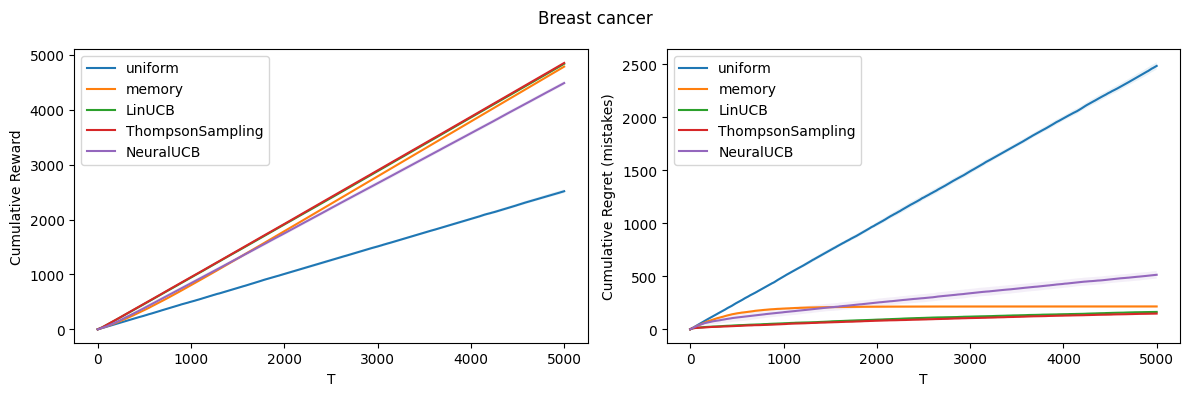

In [ ]:
times = []
time_start = time.time()
*curves_random, ctxt_bandit_algo_random = run_experiment(UniformSamplingForCB, contextual_bandits, repetitions, timesteps_per_repet)
print("UniformSampling Time :", time.time() - time_start)
times.append(time.time() - time_start)
*curves_memory, ctxt_bandit_algo_memory = run_experiment(ContextMemory, contextual_bandits, repetitions, timesteps_per_repet)
print("ContextMemory Time :", time.time() - time_start)
times.append(time.time() - time_start)
*curves_LinUCB, ctxt_bandit_algo_LinUCB = run_experiment(LinUCB, contextual_bandits, repetitions, timesteps_per_repet)
print("LinUCB Time :", time.time() - time_start)
times.append(time.time() - time_start)
*curves_TS, ctxt_bandit_algo_TS = run_experiment(ThompsonSampling, contextual_bandits, repetitions, timesteps_per_repet, seed=0, v=0.1)
print("ThompsonSampling Time :", time.time() - time_start)
times.append(time.time() - time_start)
*curves_neuralUCB, ctxt_bandit_algo_neuralUCB = run_experiment(
    NeuralUCB, contextual_bandits, repetitions, timesteps_per_repet,
    lambda_reg=0.1, gamma=0.1, L=1, m=10, J=300, tau=0.01, gamma_decay=0.95, inverse_diag=True,
    warmup=50, update_freq=50
)
print("NeuralUCB Time :", time.time() - time_start)
times.append(time.time() - time_start)
plot_results({'uniform': curves_random, 'memory': curves_memory, 'LinUCB': curves_LinUCB, 'ThompsonSampling': curves_TS, 'NeuralUCB': curves_neuralUCB}, 'Breast cancer')

In [27]:
for name, algo in [("random", ctxt_bandit_algo_random), ("Memory-based", ctxt_bandit_algo_memory), ('LinUCB', ctxt_bandit_algo_LinUCB), ('ThompsonSampling', ctxt_bandit_algo_TS), ('NeuralUCB', ctxt_bandit_algo_neuralUCB)]:
    print(f"{name}: train misclassif {get_misclassif(X_train, y_train, algo):.1f} %, test misclassif {get_misclassif(X_test, y_test, algo):.1f} %")

# Full-information reference: a logistic regression trained on all the training labels
full_information = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
print(f"Logistic regression (all labels): train misclassif {100 * (1 - full_information.score(X_train, y_train)):.1f} %, test misclassif {100 * (1 - full_information.score(X_test, y_test)):.1f} %")

random: train misclassif 50.5 %, test misclassif 50.3 %
Memory-based: train misclassif 0.0 %, test misclassif 50.3 %
LinUCB: train misclassif 1.9 %, test misclassif 2.8 %
ThompsonSampling: train misclassif 2.1 %, test misclassif 2.8 %
NeuralUCB: train misclassif 8.5 %, test misclassif 5.6 %
Logistic regression (all labels): train misclassif 1.4 %, test misclassif 2.1 %


### Handwritten digits dataset (10 classes)

In [14]:
X_digits, y_digits = datasets.load_digits(return_X_y=True)
Xd_train, Xd_test, yd_train, yd_test = split(X_digits, y_digits, test_size=0.25, random_state=42)
contextual_bandits_digits = SupervisedLearningAsBandits(Xd_train, yd_train)

UniformSampling Time: 0.1148984432220459
ContextMemory Time: 0.3885219097137451
LinUCB Time: 13.098016738891602
ThompsonSampling Time: 994.6399791240692
NeuralUCB Time: 1635.3636348247528


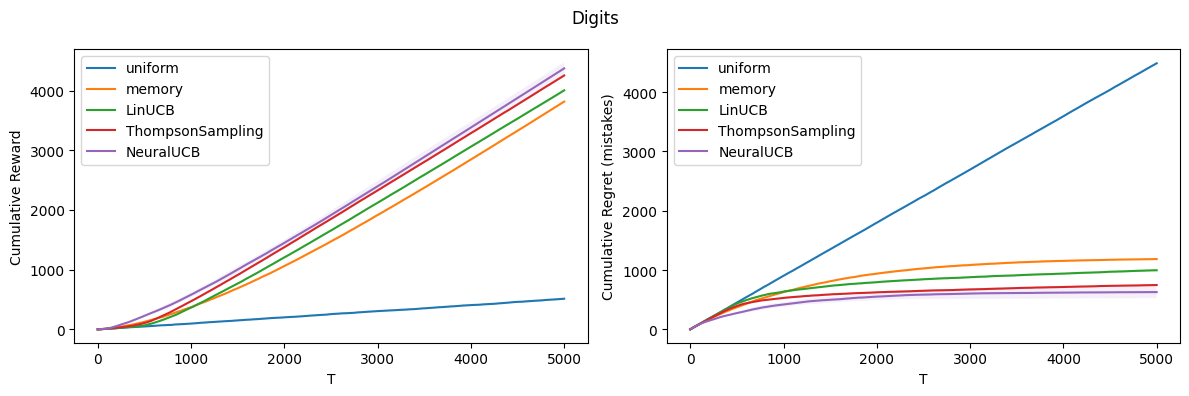

In [15]:
times = []
time_start = time.time()
*curves_random_digits, ctxt_bandit_algo_random_digits = run_experiment(UniformSamplingForCB, contextual_bandits_digits, repetitions, timesteps_per_repet)
print("UniformSampling Time:", time.time() - time_start)
times.append(time.time() - time_start)
*curves_memory_digits, ctxt_bandit_algo_memory_digits = run_experiment(ContextMemory, contextual_bandits_digits, repetitions, timesteps_per_repet)
print("ContextMemory Time:", time.time() - time_start)
times.append(time.time() - time_start)
*curves_LinUCB_digits, ctxt_bandit_algo_LinUCB_digits = run_experiment(LinUCB, contextual_bandits_digits, repetitions, timesteps_per_repet)
print("LinUCB Time:", time.time() - time_start)
times.append(time.time() - time_start)
*curves_TS_digits, ctxt_bandit_algo_TS_digits = run_experiment(ThompsonSampling, contextual_bandits_digits, repetitions, timesteps_per_repet, seed=0, v=0.1)
print("ThompsonSampling Time:", time.time() - time_start)
times.append(time.time() - time_start)
*curves_neuralUCB_digits, ctxt_bandit_algo_neuralUCB_digits = run_experiment(
    NeuralUCB, contextual_bandits_digits, repetitions, timesteps_per_repet,
    lambda_reg=0.1, gamma=0.1, L=1, m=100, J=500, tau=0.01, gamma_decay=0.99, inverse_diag=True,
    warmup=50, update_freq=50
)
print("NeuralUCB Time:", time.time() - time_start)
times.append(time.time() - time_start)
plot_results({'uniform': curves_random_digits, 'memory': curves_memory_digits, 'LinUCB':curves_LinUCB_digits, 'ThompsonSampling': curves_TS_digits, 'NeuralUCB': curves_neuralUCB_digits}, 'Digits')

In [16]:
for name, algo in [("random", ctxt_bandit_algo_random_digits), ("Memory-based", ctxt_bandit_algo_memory_digits), ("LinUCB", ctxt_bandit_algo_LinUCB_digits), ("ThompsonSampling", ctxt_bandit_algo_TS_digits), ("NeuralUCB", ctxt_bandit_algo_neuralUCB_digits)]:
    print(f"{name}: train misclassif {get_misclassif(Xd_train, yd_train, algo):.1f} %, test misclassif {get_misclassif(Xd_test, yd_test, algo):.1f} %")

full_information_digits = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(Xd_train, yd_train)
print(f"Logistic regression (all labels): train misclassif {100 * (1 - full_information_digits.score(Xd_train, yd_train)):.1f} %, test misclassif {100 * (1 - full_information_digits.score(Xd_test, yd_test)):.1f} %")

random: train misclassif 90.0 %, test misclassif 92.2 %
Memory-based: train misclassif 2.2 %, test misclassif 92.2 %
LinUCB: train misclassif 4.8 %, test misclassif 10.0 %
ThompsonSampling: train misclassif 2.6 %, test misclassif 5.1 %
NeuralUCB: train misclassif 0.5 %, test misclassif 2.4 %
Logistic regression (all labels): train misclassif 0.1 %, test misclassif 2.9 %
